### Vicarious gain from surrogate retrievals

- $g_1 = R_\mathrm{fit} / R_\mathrm{obs}$ — fit vs noisy spectrum (includes measurement noise)
- $g_2 = R_\mathrm{fit} / R_\mathrm{clean}$ — fit vs de-noised spectrum (forward-model error only)

In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

ret_dir = Path(
    "/home/zhe2/FraLab/PACE_redSIF_PACE/surrogate_meas/full_RT_construction/"
    "output_new_Lambertian_gchpio_finerwavnum0p05"
)
# retrievals to compare (relative to ret_dir, or absolute)
ret_files = [
    "rt_retrieval_1000_O2A_ScatteringIncludedSVD_nPC15_npoly3.nc",
    "rt_retrieval_1000_O2A_SIF678BandMismatch_nPC15_npoly3.nc",
]
# status: 1 converged, 0 max steps, 2 stalled, 4 failed, -1 all
keep_status = (-1,)
# use only samples that pass keep_status in every retrieval
# (requires all retrievals to share the same input ensemble)
common_samples = True

colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

keep_status = tuple(np.atleast_1d(keep_status).tolist())
keep_all = -1 in keep_status

runs = {}
for f in ret_files:
    path = Path(f) if Path(f).is_absolute() else ret_dir / f
    ds = xr.open_dataset(path)
    label = f"{ds.attrs.get('label', path.stem)} {ds.attrs.get('rank_tag', '')}".strip()
    R_fit = ds["R_fit"].values.astype(float)  # (sample, band)
    runs[label] = dict(
        path=path,
        input_ensemble=ds.attrs.get("input_ensemble", ""),
        wl=ds["wavelength"].values,
        g1_all=R_fit / ds["R_obs"].values.astype(float),
        g2_all=R_fit / ds["R_clean"].values.astype(float),
        ok=(keep_all | np.isin(ds["status"].values, keep_status)) & np.all(np.isfinite(R_fit), axis=1),
    )
    ds.close()

if common_samples and len(runs) > 1:
    ens = {r["input_ensemble"] for r in runs.values()}
    n_samp = {r["ok"].size for r in runs.values()}
    assert len(ens) == 1 and len(n_samp) == 1, (
        f"common_samples needs one shared input ensemble; got {ens}"
    )
    ok_common = np.logical_and.reduce([r["ok"] for r in runs.values()])
    for r in runs.values():
        r["ok"] = ok_common

for label, r in runs.items():
    r["g1"] = r["g1_all"][r["ok"]]
    r["g2"] = r["g2_all"][r["ok"]]
    print(f"{label}: {r['ok'].sum()} / {r['ok'].size} samples  ({r['path'].name})")

1000_O2A_ScatteringIncludedSVD nPC15_npoly3: 1000 / 1000 samples  (rt_retrieval_1000_O2A_ScatteringIncludedSVD_nPC15_npoly3.nc)
1000_O2A_SIF678BandMismatch nPC15_npoly3: 1000 / 1000 samples  (rt_retrieval_1000_O2A_SIF678BandMismatch_nPC15_npoly3.nc)


In [17]:
# Summary: gain over all bands and samples (in %)
rows = []
for label, r in runs.items():
    for name in ("g1", "g2"):
        g = r[name]
        med_spec = np.median(g, axis=0)
        rows.append({
            "retrieval": label,
            "gain": name,
            "n": len(g),
            "median (g-1) %": (np.median(g) - 1) * 100,
            "std %": g.std() * 100,
            "max |median_λ(g)-1| %": np.abs(med_spec - 1).max() * 100,
            "rms median_λ(g)-1 %": np.sqrt(np.mean((med_spec - 1) ** 2)) * 100,
        })
pd.DataFrame(rows).set_index(["retrieval", "gain"]).round(4)

n  median (g-1) %  \
retrieval                                   gain                         
1000_O2A_ScatteringIncludedSVD nPC15_npoly3 g1    1000          0.0266   
                                            g2    1000          0.0197   
1000_O2A_SIF678BandMismatch nPC15_npoly3    g1    1000          0.0016   
                                            g2    1000         -0.0072   

                                                   std %  \
retrieval                                   gain           
1000_O2A_ScatteringIncludedSVD nPC15_npoly3 g1    0.3382   
                                            g2    0.3151   
1000_O2A_SIF678BandMismatch nPC15_npoly3    g1    0.2533   
                                            g2    0.2216   

                                                  max |median_λ(g)-1| %  \
retrieval                                   gain                          
1000_O2A_ScatteringIncludedSVD nPC15_npoly3 g1                   0.4128   
                                            g2                   0.3834   
1000_O2A_SIF678BandMismatch nPC15_npoly3    g1                   0.7447   
                                            g2                   0.7896   

                                                  rms median_λ(g)-1 %  
retrieval                                   gain                       
1000_O2A_ScatteringIncludedSVD nPC15_npoly3 g1                 0.1215  
                                            g2                 0.1065  
1000_O2A_SIF678BandMismatch nPC15_npoly3    g1                 0.1847  
                                            g2                 0.1900

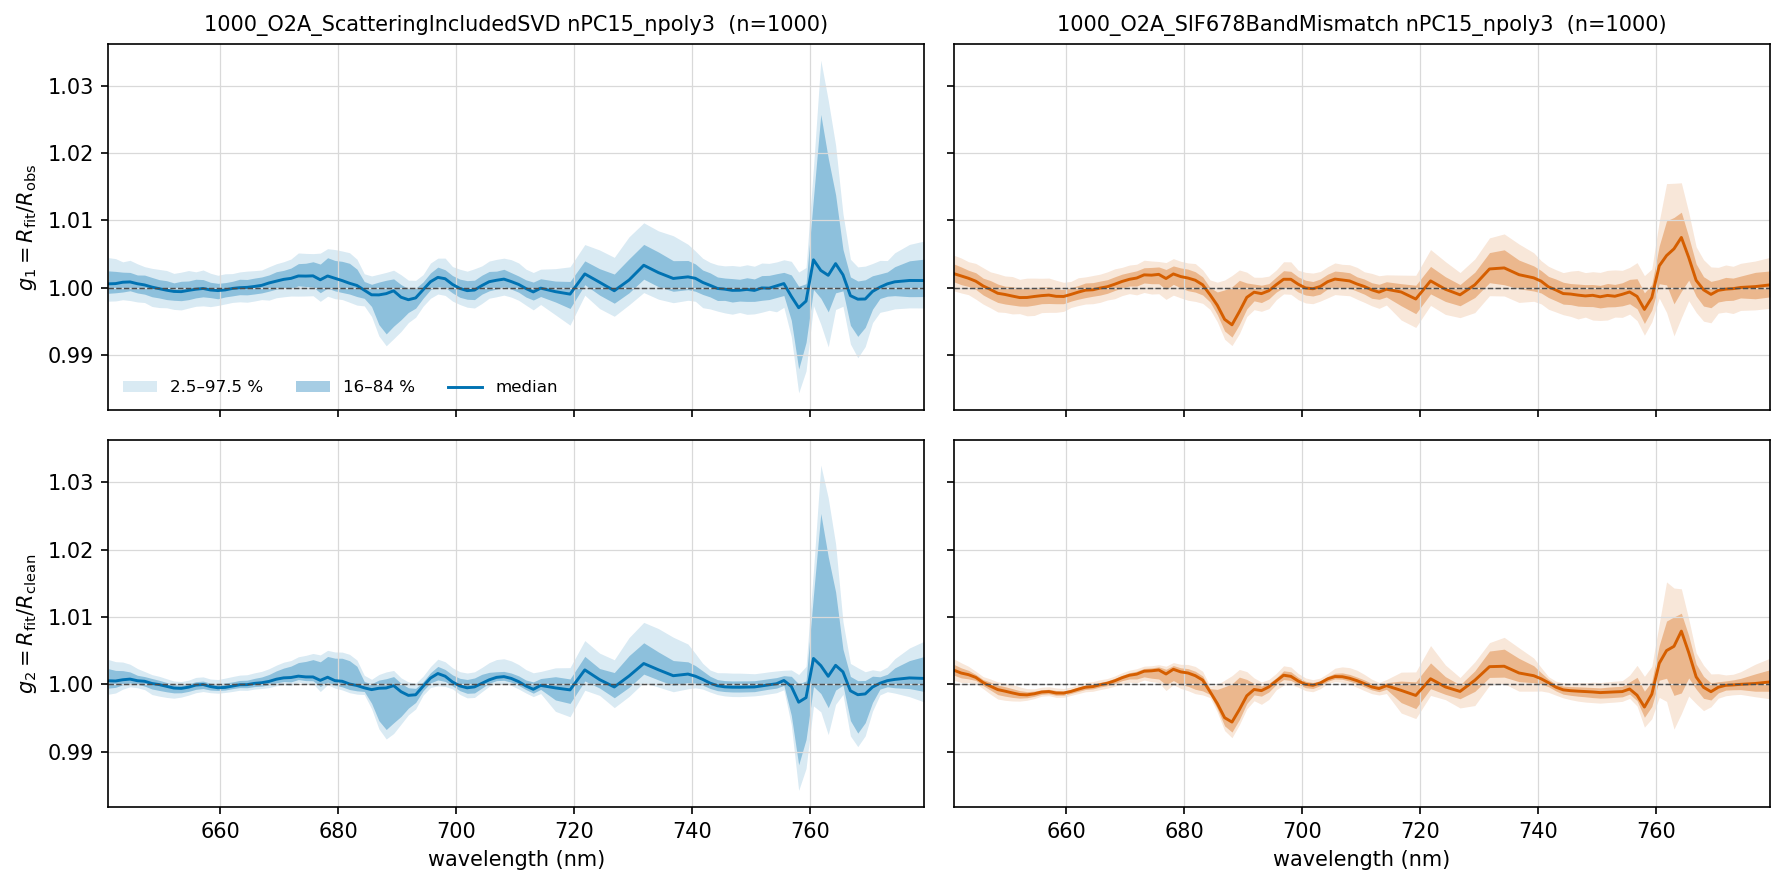

In [18]:
# Spectral gain per retrieval: median with 16–84 % and 2.5–97.5 % ensemble envelopes
def _plot_gain(ax, wl, g, color):
    p = np.percentile(g, [2.5, 16, 50, 84, 97.5], axis=0)
    ax.fill_between(wl, p[0], p[4], color=color, alpha=0.15, lw=0, label="2.5–97.5 %")
    ax.fill_between(wl, p[1], p[3], color=color, alpha=0.35, lw=0, label="16–84 %")
    ax.plot(wl, p[2], "-", color=color, lw=1.4, label="median")
    ax.axhline(1.0, color="0.3", lw=0.7, ls="--")

n_run = len(runs)
fig, axes = plt.subplots(
    2, n_run, figsize=(6 * n_run, 6), dpi=150, sharex=True, sharey=True, squeeze=False,
)
for j, (label, r) in enumerate(runs.items()):
    c = colors[j % len(colors)]
    _plot_gain(axes[0, j], r["wl"], r["g1"], c)
    _plot_gain(axes[1, j], r["wl"], r["g2"], c)
    axes[0, j].set_title(f"{label}  (n={len(r['g1'])})", fontsize=10)
    axes[1, j].set_xlabel("wavelength (nm)")
axes[0, 0].set_ylabel(r"$g_1 = R_\mathrm{fit}/R_\mathrm{obs}$")
axes[1, 0].set_ylabel(r"$g_2 = R_\mathrm{fit}/R_\mathrm{clean}$")
axes[0, 0].legend(loc="lower left", fontsize=8, frameon=False, ncol=3)
for a in axes.flat:
    a.grid(True, color="0.85", lw=0.6)
    a.set_xlim(min(r["wl"].min() for r in runs.values()), max(r["wl"].max() for r in runs.values()))
plt.tight_layout()
plt.show()

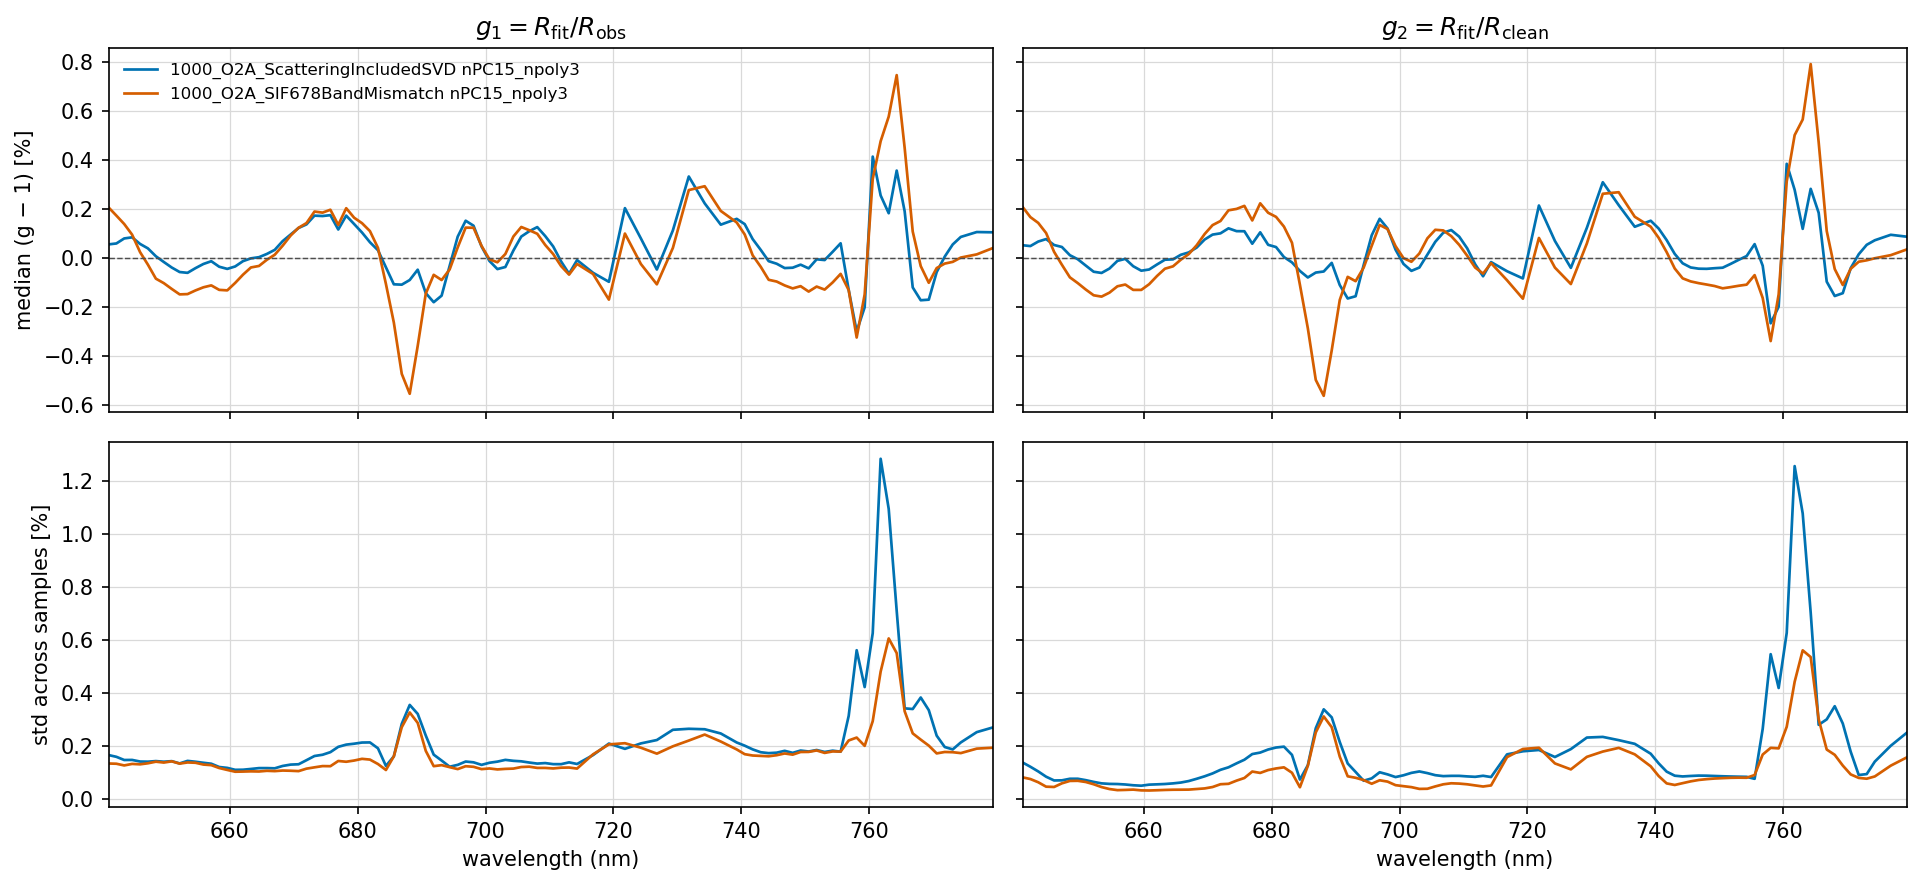

In [19]:
# Compare retrievals directly: median bias (top) and ensemble spread (bottom), g1 left / g2 right
fig, axes = plt.subplots(2, 2, figsize=(13, 6), dpi=150, sharex=True, sharey="row")
for j, (label, r) in enumerate(runs.items()):
    c = colors[j % len(colors)]
    for k, name in enumerate(("g1", "g2")):
        g = r[name]
        axes[0, k].plot(r["wl"], (np.median(g, axis=0) - 1) * 100, "-", color=c, lw=1.3, label=label)
        axes[1, k].plot(r["wl"], g.std(axis=0) * 100, "-", color=c, lw=1.3, label=label)

axes[0, 0].set_title(r"$g_1 = R_\mathrm{fit}/R_\mathrm{obs}$")
axes[0, 1].set_title(r"$g_2 = R_\mathrm{fit}/R_\mathrm{clean}$")
axes[0, 0].set_ylabel("median (g − 1) [%]")
axes[1, 0].set_ylabel("std across samples [%]")
for a in axes[0]:
    a.axhline(0.0, color="0.3", lw=0.7, ls="--")
for a in axes[1]:
    a.set_xlabel("wavelength (nm)")
for a in axes.flat:
    a.grid(True, color="0.85", lw=0.6)
    a.set_xlim(min(r["wl"].min() for r in runs.values()), max(r["wl"].max() for r in runs.values()))
axes[0, 0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()